In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn import tree
from sklearn.metrics import roc_curve, auc, RocCurveDisplay, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, PrecisionRecallDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay, average_precision_score
from sklearn.tree import DecisionTreeClassifier
import joblib
import os


In [6]:
df = pd.read_csv('StressLevelDataset.csv')
df.shape[0]

1100

In [7]:
df['stress_level'].unique()

array([1, 2, 0], dtype=int64)

In [8]:
df.describe()

,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
count,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,...,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000
mean,11.063636,17.777273,0.492727,12.555455,2.508182,2.181818,2.660000,2.753636,2.649091,2.518182,...,2.772727,2.772727,2.621818,2.648182,2.649091,1.881818,2.734545,2.767273,2.617273,0.996364
std,6.117558,8.944599,0.500175,7.727008,1.409356,0.833575,1.548383,1.400713,1.328127,1.119208,...,1.433761,1.414594,1.315781,1.384579,1.529375,1.047826,1.425265,1.417562,1.530958,0.821673
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.000000,11.000000,0.000000,6.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,...,2.000000,2.000000,2.000000,2.000000,1.000000,1.000000,2.000000,2.000000,1.000000,0.000000
50%,11.000000,19.000000,0.000000,12.000000,3.000000,2.000000,2.500000,3.000000,3.000000,2.000000,...,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.500000,3.000000,1.000000
75%,16.000000,26.000000,1.000000,19.000000,3.000000,3.000000,4.000000,4.000000,3.000000,3.000000,...,4.000000,4.000000,3.000000,4.000000,4.000000,3.000000,4.000000,4.000000,4.000000,2.000000
max,21.000000,30.000000,1.000000,27.000000,5.000000,3.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,3.000000,5.000000,5.000000,5.000000,2.000000


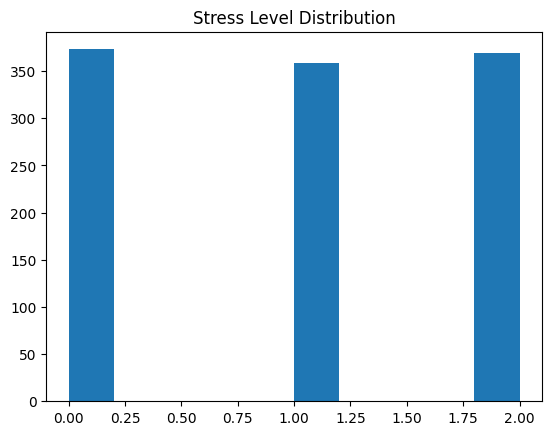

In [9]:

plt.hist(df['stress_level'])
plt.title("Stress Level Distribution")
plt.show()

In [10]:
features, label = df.iloc[:,:-1], df["stress_level"]
X_train, X_test, y_train, y_test = train_test_split(features, label, test_size=0.2, random_state=1, stratify=label)
scaler = preprocessing.StandardScaler().fit(X_train)

In [11]:
scaled_train_df = scaler.transform(X_train)
scaled_test_df = scaler.transform(X_test)

In [12]:
for k in range(1,20):
    knn = KNeighborsClassifier(n_neighbors = k)
    knn.fit(scaled_train_df,y_train)
    print('k = ' +str(k)+', score: '+str(knn.score(scaled_test_df, y_test)))

k = 1, score: 0.8727272727272727
k = 2, score: 0.85
k = 3, score: 0.8590909090909091
k = 4, score: 0.8454545454545455
k = 5, score: 0.8590909090909091
k = 6, score: 0.8590909090909091
k = 7, score: 0.8545454545454545
k = 8, score: 0.8636363636363636
k = 9, score: 0.8590909090909091
k = 10, score: 0.8636363636363636
k = 11, score: 0.8590909090909091
k = 12, score: 0.8681818181818182
k = 13, score: 0.8636363636363636
k = 14, score: 0.8636363636363636
k = 15, score: 0.8636363636363636
k = 16, score: 0.8636363636363636
k = 17, score: 0.8636363636363636
k = 18, score: 0.8681818181818182
k = 19, score: 0.8636363636363636


C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)
C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will

In [13]:
#k-fold cross validaton
from sklearn.model_selection import cross_val_score
for k in range(1,40):
    knn_cv = KNeighborsClassifier(n_neighbors = k)

    cv_scores = cross_val_score(knn_cv, scaled_train_df, y_train, cv=5)

    #print each cv score (accuracy) and average them
#     print(cv_scores)
#     print('cv_scores mean:{}'.format(np.mean(cv_scores)))
    print('k = ' +str(k)+', score: '+str(np.mean(cv_scores)))

C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)
C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will

k = 1, score: 0.8863636363636364
k = 2, score: 0.8727272727272727
k = 3, score: 0.8693181818181819
k = 4, score: 0.8704545454545455
k = 5, score: 0.871590909090909


C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)
C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will

k = 6, score: 0.8704545454545455
k = 7, score: 0.871590909090909
k = 8, score: 0.8693181818181817
k = 9, score: 0.8704545454545454
k = 10, score: 0.8704545454545455


C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)
C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will

...

C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)
C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will

k = 27, score: 0.8704545454545454
k = 28, score: 0.871590909090909
k = 29, score: 0.871590909090909
k = 30, score: 0.871590909090909
k = 31, score: 0.8693181818181817


C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)
C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will

k = 32, score: 0.871590909090909
k = 33, score: 0.871590909090909
k = 34, score: 0.8727272727272727
k = 35, score: 0.871590909090909
k = 36, score: 0.8727272727272727
k = 37, score: 0.871590909090909
k = 38, score: 0.871590909090909
k = 39, score: 0.871590909090909


C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)
C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will

In [14]:
#create new a knn model pipeline
knn_pipeline = Pipeline(steps=[("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
#create a dictionary of all parameters we want to find out the best parameter
param_grid = {'knn__n_neighbors': np.arange(1, 40)}
#use gridsearch to test all values for n_neighbors
knn_gscv = GridSearchCV(knn_pipeline, param_grid, cv=5)
#fit model to data
knn_gscv.fit(X_train, y_train)

knn_best_pipeline = knn_gscv.best_estimator_
print(knn_gscv.best_params_)
print(knn_gscv.best_score_)
# print(knn_best_model)

C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)
C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will

{'knn__n_neighbors': 1}
0.8863636363636364


C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)
C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will

In [15]:
#create new a decision tree model pipeline
dt_pipeline = Pipeline(steps=[("scaler", StandardScaler()), ("dt", tree.DecisionTreeClassifier())])
param_grid = {'dt__max_depth':range(1,20)}
# Grid search to get the best decision tree model
dt_gscv = GridSearchCV(dt_pipeline, param_grid, n_jobs=4, cv=5)

dt_gscv.fit(X_train, y_train)

dt_best_pipeline = dt_gscv.best_estimator_
print (dt_gscv.best_score_, dt_gscv.best_params_)
# print(dt_best_model)

0.8897727272727274 {'dt__max_depth': 4}


[Text(251.72596153846155, 355.38461538461536, 'X[5] <= 1.5\ngini = 0.667\nsamples = 880\nvalue = [299, 286, 295]'),
 Text(242.1875, 326.95384615384614, 'gini = 0.0\nsamples = 243\nvalue = [0, 243, 0]'),
 Text(261.2644230769231, 326.95384615384614, 'X[1] <= 15.5\ngini = 0.561\nsamples = 637\nvalue = [299, 43, 295]'),
 Text(140.9903846153846, 298.5230769230769, 'X[19] <= 3.5\ngini = 0.25\nsamples = 322\nvalue = [28, 17, 277]'),
 Text(72.13461538461539, 270.09230769230766, 'X[8] <= 0.5\ngini = 0.633\nsamples = 62\nvalue = [22, 12, 28]'),
 Text(38.15384615384615, 241.66153846153844, 'X[3] <= 7.5\ngini = 0.403\nsamples = 12\nvalue = [9, 2, 1]'),
 Text(28.615384615384613, 213.2307692307692, 'X[0] <= 10.0\ngini = 0.625\nsamples = 4\nvalue = [1, 2, 1]'),
 Text(19.076923076923077, 184.79999999999998, 'X[7] <= 0.5\ngini = 0.5\nsamples = 2\nvalue = [1, 0, 1]'),
 Text(9.538461538461538, 156.36923076923074, 'gini = 0.0\nsamples = 1\nvalue = [0, 0, 1]'),
 Text(28.615384615384613, 156.36923076923074,

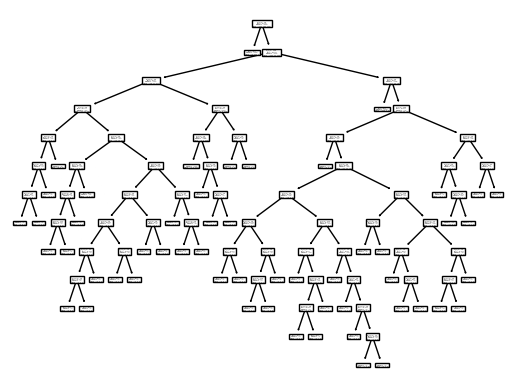

In [16]:
dt_best_model = DecisionTreeClassifier()
dt_best_model.fit(X_train, y_train)

tree.plot_tree(dt_best_model)

In [17]:
#create new a random forest tree model pipeline
rft_pipeline = Pipeline(steps=[("scaler", StandardScaler()), ("rft", RandomForestClassifier(random_state=0))])
param_grid = {'rft__max_depth':range(1,20)}

# Grid search to get the best random forest tree model
rft_gscv = GridSearchCV(rft_pipeline, param_grid, n_jobs=4, cv=5)

rft_gscv.fit(X_train, y_train)

rft_best_pipeline = rft_gscv.best_estimator_
print(rft_gscv.best_score_, rft_gscv.best_params_)
# print(rft_best_model)

0.8863636363636364 {'rft__max_depth': 9}


In [19]:
from sklearn.metrics import accuracy_score

# KNN
pred = knn_best_pipeline.predict(X_test)
print("KNN Accuracy:", accuracy_score(y_test, pred))

# Decision Tree
pred = dt_best_pipeline.predict(X_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, pred))

# Random Forest
pred = rft_best_pipeline.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(y_test, pred))

KNN Accuracy: 0.8727272727272727
Decision Tree Accuracy: 0.8818181818181818
Random Forest Accuracy: 0.8727272727272727


C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)


In [21]:
from sklearn.metrics import accuracy_score, classification_report

# KNN
pred = knn_best_pipeline.predict(X_test)
print("KNN Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred))

# Decision Tree
pred = dt_best_pipeline.predict(X_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred))

# Random Forest
pred = rft_best_pipeline.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred))

KNN Accuracy: 0.8727272727272727
              precision    recall  f1-score   support

           0       0.88      0.89      0.89        74
           1       0.87      0.85      0.86        72
           2       0.87      0.88      0.87        74

    accuracy                           0.87       220
   macro avg       0.87      0.87      0.87       220
weighted avg       0.87      0.87      0.87       220

Decision Tree Accuracy: 0.8818181818181818
              precision    recall  f1-score   support

           0       0.84      0.95      0.89        74
           1       1.00      0.79      0.88        72
           2       0.84      0.91      0.87        74

    accuracy                           0.88       220
   macro avg       0.89      0.88      0.88       220
weighted avg       0.89      0.88      0.88       220

Random Forest Accuracy: 0.8727272727272727
              precision    recall  f1-score   support

           0       0.82      0.93      0.87        74
          

C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)


In [23]:
from sklearn.metrics import accuracy_score, classification_report

# KNN
pred = knn_best_pipeline.predict(X_test)
print("KNN Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred))

# Decision Tree
pred = dt_best_pipeline.predict(X_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred))

# Random Forest
pred = rft_best_pipeline.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred))

KNN Accuracy: 0.8727272727272727
              precision    recall  f1-score   support

           0       0.88      0.89      0.89        74
           1       0.87      0.85      0.86        72
           2       0.87      0.88      0.87        74

    accuracy                           0.87       220
   macro avg       0.87      0.87      0.87       220
weighted avg       0.87      0.87      0.87       220

Decision Tree Accuracy: 0.8818181818181818
              precision    recall  f1-score   support

           0       0.84      0.95      0.89        74
           1       1.00      0.79      0.88        72
           2       0.84      0.91      0.87        74

    accuracy                           0.88       220
   macro avg       0.89      0.88      0.88       220
weighted avg       0.89      0.88      0.88       220

Random Forest Accuracy: 0.8727272727272727
              precision    recall  f1-score   support

           0       0.82      0.93      0.87        74
          

C:\Users\srina\AppData\Roaming\Python\Python38\site-packages\sklearn\neighbors\_classification.py:187: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)


In [24]:
joblib.dump(rft_best_pipeline, "mental_health_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
import os
print(os.listdir())

['DM Project Presentation.pptx', 'mental_health_model.pkl', 'mental_health_model1.pkl', 'README.md', 'StressLevelDataset.csv', 'student_strss_prediction.ipynb']


In [ ]:
import joblib
import numpy as np

# load model
model = joblib.load("mental_health_model.pkl")

# example input (same order as dataset features)
sample = [[3,4,2,3,1,4,2,3,2,4,3,2]]

prediction = model.predict(sample)

print("Predicted Stress Level:", prediction)

ValueError: operands could not be broadcast together with shapes (1,12) (20,) (1,12) 

In [ ]:
print(model.named_steps)

{'scaler': StandardScaler(copy=True, with_mean=True, with_std=True), 'rft': RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=10, max_features='auto',
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_impurity_split=None,
                       min_samples_leaf=1, min_samples_split=2,
                       min_weight_fraction_leaf=0.0, n_estimators=100,
                       n_jobs=None, oob_score=False, random_state=0, verbose=0,
                       warm_start=False)}


In [ ]:
import pandas as pd
import joblib

# load dataset
df = pd.read_csv("StressLevelDataset.csv")

# load model
model = joblib.load("mental_health_model.pkl")

# take one sample
sample = df.drop("stress_level", axis=1).iloc[[0]]

prediction = model.predict(sample)

print("Predicted Stress Level:", prediction)

Predicted Stress Level: [1]


In [ ]:
stress_labels = {
    0: "Low Stress",
    1: "Medium Stress",
    2: "High Stress"
}

print("Predicted Stress Level:", stress_labels[prediction[0]])

Predicted Stress Level: Medium Stress


In [ ]:
import pandas as pd

df = pd.read_csv("StressLevelDataset.csv")

print(df.columns)

Index(['anxiety_level', 'self_esteem', 'mental_health_history', 'depression',
       'headache', 'blood_pressure', 'sleep_quality', 'breathing_problem',
       'noise_level', 'living_conditions', 'safety', 'basic_needs',
       'academic_performance', 'study_load', 'teacher_student_relationship',
       'future_career_concerns', 'social_support', 'peer_pressure',
       'extracurricular_activities', 'bullying', 'stress_level'],
      dtype='object')


In [25]:
print(df["stress_level"].value_counts())

stress_level
0    373
2    369
1    358
Name: count, dtype: int64
